# Экзаменационная задача №2. Расчет критической массы и ценности социальной сети

- **Курс:** Экономика информатизации, лекция №3 «Сетевые эффекты и критическая масса»
- **Студент:** Солдатов Сергей Юрьевич
- **Группа:** ПИ4-1
- **Дата:** 2026-11-17

In [1]:
# ============================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №02: РАСЧЕТ КРИТИЧЕСКОЙ МАССЫ И ЦЕННОСТИ
#                             СОЦИАЛЬНОЙ СЕТИ
# ============================================================================
# Дата: 2026-11-17
# Студент: Солдатов Сергей Юрьевич
# Группа: ПИ4-1
# ============================================================================

# Библиотеки: numpy и pandas — расчеты и таблицы, matplotlib — графики
import json
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

MLN = 1_000_000  # рублей в миллионе


def fmt(value, digits=0):
    """Число в привычной записи: 133 334 или 60,10."""
    value = round(value, digits) + 0          # «+ 0» убирает минус у нуля
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",").replace("-", "−")


def pct(value, digits=0):
    """Доля в процентах: 0.03 -> 3%."""
    return fmt(value * 100, digits) + "%"


def signed(value, digits=0):
    """Число со знаком: +19,7 или −0,46."""
    return ("+" if value > 0 else "") + fmt(value, digits)


# Числа в таблицах pandas показываем в том же формате, с двумя знаками
pd.options.display.float_format = lambda value: fmt(value, 2)

# Единый вид графиков: светлый фон, сетка, без верхней и правой рамки
plt.rcParams.update({
    "figure.figsize": (9, 4.8),
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

# Цвета линий на графиках
BLUE, ORANGE, GREEN, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"

# Графики сохраняем в reports/figures (ноутбук запускается из папки notebooks)
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

## Экономическая постановка задачи

**Проблема.** Компания «ГородСоцСеть» запускает социальную сеть для города с населением 1 млн человек. У соцсети есть
прямой сетевой эффект: чем больше в ней людей, тем она полезнее каждому. Пока пользователей мало, сеть малополезна
и убыточна. После **критической массы** она начинает поддерживать себя сама.

**Актуальность.** Для платформы главный вопрос — не «сколько стоит разработка», а «хватит ли денег дожить до
критической массы». От ответа зависят объем инвестиций и стратегия запуска.

**Цель.** Оценить ценность сети, найти момент достижения критической массы и эффективность проекта за 36 месяцев.

**Задачи:**
1. найти критическую массу и срок ее достижения;
2. посчитать ценность сети по закону Мэткалфа, доход и прибыль по месяцам;
3. посчитать NPV, проверить его при других темпах роста и найти минимальный ARPU;
4. оценить, сколько стоит ускорение на 6 месяцев, и предложить стратегию.

## 1. Исходные данные

### 1.1. Параметры проекта

Все значения взяты из условия задачи (методичка, лекция №3, раздел «Экзаменационная задача»).

In [2]:
# Все исходные данные лежат в одном словаре: меняем значение здесь — пересчитывается всё
BASE = {
    "market": 1_000_000,     # M — потенциал рынка, чел.
    "start_users": 5_000,    # N0 — пользователей на старте, чел.
    "growth_before": 0.03,   # прирост в месяц до критической массы
    "growth_after": 0.15,    # прирост в месяц после критической массы
    "k": 0.005,              # коэффициент ценности сети, руб./пользователь²
    "support": 2_000_000,    # F — затраты на поддержание сети, руб./мес.
    "cac": 500,              # CAC — стоимость привлечения пользователя, руб.
    "arpu": 15,              # ARPU — доход с пользователя, руб./мес.
    "months": 36,            # горизонт оценки, мес.
    "rate": 0.01,            # ставка дисконтирования в месяц (12% годовых)
}

# Таблица строится из словаря, поэтому всегда совпадает с расчетом
source_table = pd.DataFrame(
    [
        ("Потенциал рынка (M), чел.", fmt(BASE["market"])),
        ("Начальное число пользователей (N0), чел.", fmt(BASE["start_users"])),
        ("Прирост в месяц до критической массы", pct(BASE["growth_before"])),
        ("Прирост в месяц после критической массы", pct(BASE["growth_after"])),
        ("Коэффициент ценности сети (k), руб./польз.²", fmt(BASE["k"], 3)),
        ("Затраты на поддержание сети (F), руб./мес.", fmt(BASE["support"])),
        ("Стоимость привлечения пользователя (CAC), руб.", fmt(BASE["cac"])),
        ("Доход с пользователя (ARPU), руб./мес.", fmt(BASE["arpu"])),
        ("Горизонт оценки, мес.", fmt(BASE["months"])),
        ("Ставка дисконтирования, в месяц", pct(BASE["rate"])),
    ],
    columns=["Параметр", "Значение"],
)
display(source_table)

,Параметр,Значение
0,"Потенциал рынка (M), чел.",1 000 000
1,"Начальное число пользователей (N0), чел.",5 000
2,Прирост в месяц до критической массы,3%
3,Прирост в месяц после критической массы,15%
4,"Коэффициент ценности сети (k), руб./польз.²","0,005"
5,"Затраты на поддержание сети (F), руб./мес.",2 000 000
6,"Стоимость привлечения пользователя (CAC), руб.",500
7,"Доход с пользователя (ARPU), руб./мес.",15
8,"Горизонт оценки, мес.",36
9,"Ставка дисконтирования, в месяц",1%


### 1.2. Справочные данные

**Из лекции №3:**

- закон Мэткалфа: ценность сети $V(N) = k \cdot N^2$;
- критическая масса — минимальное число пользователей, при котором сеть становится самоподдерживающейся.
  В лекции это записано как $V(N) > C(N)$, где $C(N)$ — затраты на поддержание сети.

**Из условия задачи:** критическая масса — число пользователей, при котором «доход ≥ затраты на поддержание + CAC».
Темпы роста для пессимистичного и оптимистичного сценариев заданы в задании 7.

**Сверх условия:** длинный горизонт 180 месяцев (15 лет) нужен только чтобы увидеть весь путь сети до критической
массы. Все показатели проекта считаются за 36 месяцев.

In [3]:
# Сценарии темпов роста из задания 7: (до критической массы, после нее)
GROWTH_SCENARIOS = {
    "Пессимистичный": (0.02, 0.10),
    "Базовый": (BASE["growth_before"], BASE["growth_after"]),
    "Оптимистичный": (0.05, 0.20),
}

# Длинный горизонт, чтобы увидеть весь путь сети (сверх условия)
LONG_MONTHS = 180

### 1.3. Дополнительные условия (допущения)

| № | Допущение | Почему так |
|---|---|---|
| Д1 | Критическая масса — число пользователей, при котором доход покрывает затраты на поддержание: $N_{крит} = F / ARPU$. Затраты на привлечение (CAC) считаем платой за рост и учитываем отдельно | Если CAC включить в формулу буквально, при заданных числах критической массы не существует. Расчет и два других варианта определения — в разделе 2.3 |
| Д2 | Сеть растет помесячно: $N_t = \min(M;\ N_{t-1} \cdot (1+g))$. Темп $g$ = 3%, пока пользователей меньше критической массы, потом 15% | Экспоненциальный рост по условию; пользователей не может быть больше населения города |
| Д3 | CAC платится за каждого нового пользователя весь срок | Так записана формула прибыли в условии. Вариант с бесплатным ростом после критической массы — в разделе 2.7 |
| Д4 | Оттока пользователей нет | В условии он не задан |
| Д5 | Потоки относятся на конец месяца, месяцы 1–36. Затраты на первые 5 000 пользователей уже понесены | Стандартное упрощение при расчете NPV |
| Д6 | Ценность по Мэткалфу в NPV не входит | Это оценка полезности сети, а не поступление денег. Деньги сеть получает через ARPU |

## 2. Расчеты

### 2.1. Математическая модель

**Критическая масса.** Доход $ARPU \cdot N$ должен покрывать затраты на поддержание $F$:

$$N_{крит} = \frac{F}{ARPU}$$

**Время достижения.** При росте на долю $g$ в месяц $N_t = N_0 (1+g)^t$, откуда

$$t_{крит} = \frac{\ln(N_{крит} / N_0)}{\ln(1+g)}$$

**Ценность сети (закон Мэткалфа):** $V(N) = k \cdot N^2$.

**Доход:** $R_t = ARPU \cdot N_t$.

**Прибыль:** $П_t = R_t - F - CAC \cdot (N_t - N_{t-1})$, где $N_t - N_{t-1}$ — новые пользователи месяца.

**NPV:** $NPV = \sum_{t=1}^{36} \dfrac{П_t}{(1+r)^t}$, где $r$ = 1% в месяц.

**Почему эти методы.** Закон Мэткалфа — основная модель прямого сетевого эффекта в лекции №3. NPV нужен, потому что
сеть сначала несет убытки, а доходы получает позже: сравнивать их можно только с учетом стоимости денег во времени.

### 2.2. Модель роста сети

Четыре короткие функции. Главная — `simulate`: она месяц за месяцем считает пользователей, доход, затраты и прибыль.

In [4]:
def critical_mass(p):
    """Критическая масса: доход ARPU × N покрывает затраты на поддержание."""
    return p["support"] / p["arpu"]


def simulate(p, months=None, extra_start_users=0, free_growth_after=False,
             threshold=None):
    """Помесячная модель сети: пользователи, доход, затраты, прибыль.

    months            — сколько месяцев считать (по умолчанию горизонт из p);
    extra_start_users — сколько пользователей докупаем разово на старте;
    free_growth_after — True: после критической массы рост бесплатный (без CAC);
    threshold         — порог смены темпа роста (по умолчанию критическая масса).
    """
    months = months or p["months"]
    if threshold is None:
        threshold = critical_mass(p)
    users = p["start_users"] + extra_start_users

    # Месяц 0 — старт: дохода еще нет, платим только за докупленных пользователей
    rows = [{"Месяц": 0, "Пользователи": users, "Новые": extra_start_users,
             "Доход": 0.0, "Поддержание": 0.0,
             "Привлечение": p["cac"] * extra_start_users}]

    for month in range(1, months + 1):
        reached = users >= threshold - 1e-6             # критическая масса уже набрана?
        growth = p["growth_after"] if reached else p["growth_before"]
        users_now = min(p["market"], users * (1 + growth))   # не больше рынка
        new_users = users_now - users
        is_free = free_growth_after and reached          # за этот рост платить не нужно
        rows.append({"Месяц": month, "Пользователи": users_now, "Новые": new_users,
                     "Доход": p["arpu"] * users_now, "Поддержание": p["support"],
                     "Привлечение": 0.0 if is_free else p["cac"] * new_users})
        users = users_now

    table = pd.DataFrame(rows).set_index("Месяц")
    table["Ценность"] = p["k"] * table["Пользователи"] ** 2          # закон Мэткалфа
    table["Прибыль"] = table["Доход"] - table["Поддержание"] - table["Привлечение"]
    table["Дисконт"] = 1 / (1 + p["rate"]) ** table.index            # коэффициент месяца
    table["Дисконтированная прибыль"] = table["Прибыль"] * table["Дисконт"]
    return table


def npv(table):
    """NPV: сумма дисконтированных месячных прибылей."""
    return table["Дисконтированная прибыль"].sum()


def month_reached(table, level):
    """Первый месяц, когда пользователей не меньше level (None — не достигнуто)."""
    hit = table.index[table["Пользователи"] >= level - 1e-6]
    return int(hit[0]) if len(hit) else None


def when(month):
    """Текст для вывода: «на 112-м месяце» или «не за 180 месяцев»."""
    return f"на {month}-м месяце" if month else f"не за {LONG_MONTHS} месяцев"

### 2.3. Часть 1. Критическая масса и время ее достижения (задания 1–2)

In [5]:
# Критическая масса: доход ARPU × N равен затратам на поддержание
n_crit = critical_mass(BASE)
print(f"N_крит = {fmt(BASE['support'])} / {fmt(BASE['arpu'])} = {fmt(n_crit, 1)}")
print(f"Округляем вверх: {fmt(math.ceil(n_crit))} пользователей — "
      f"{pct(n_crit / BASE['market'], 1)} населения города")
print(f"Это в {fmt(n_crit / BASE['start_users'], 1)} раза больше стартовой базы")

N_крит = 2 000 000 / 15 = 133 333,3
Округляем вверх: 133 334 пользователей — 13,3% населения города
Это в 26,7 раза больше стартовой базы


**Как учтен CAC.** В условии сказано: «доход ≥ затраты на поддержание + CAC». Если сеть растет на долю $g$ в месяц
и за рост платит из дохода, новых пользователей за месяц $g \cdot N$, и условие превращается в

$$ARPU \cdot N \ge F + CAC \cdot g \cdot N \quad\Rightarrow\quad N_{крит}(g) = \frac{F}{ARPU - CAC \cdot g}$$

Таблица ниже показывает, что получается при разных темпах роста.

In [6]:
# Сколько из ARPU уходит на оплату роста и какая получается критическая масса
rows = []
for growth in sorted({0, 0.01, 0.02, BASE["growth_before"], BASE["growth_after"]}):
    spend = BASE["cac"] * growth                 # расход на рост на одного пользователя
    left = BASE["arpu"] - spend                  # что остается на поддержание сети
    mass = fmt(BASE["support"] / left) if left > 1e-9 else "не существует"
    rows.append((pct(growth), fmt(spend, 1), fmt(left, 1), mass))
cac_table = pd.DataFrame(rows, columns=[
    "Платный рост в месяц", "Расход на рост, руб. на пользователя",
    "Остается от ARPU, руб.", "Критическая масса, польз.",
])
display(cac_table)

# Самый быстрый рост, который сеть может оплатить из своего дохода
print(f"Доход окупает рост только при темпе ниже ARPU / CAC = "
      f"{pct(BASE['arpu'] / BASE['cac'], 1)} в месяц")

,Платный рост в месяц,"Расход на рост, руб. на пользователя","Остается от ARPU, руб.","Критическая масса, польз."
0,0%,"0,0","15,0",133 333
1,1%,"5,0","10,0",200 000
2,2%,"10,0","5,0",400 000
3,3%,"15,0","0,0",не существует
4,15%,"75,0","−60,0",не существует


Доход окупает рост только при темпе ниже ARPU / CAC = 3,0% в месяц


**Вывод по CAC.** При темпе 3% расход на рост равен 500 × 3% = 15 руб. на пользователя в месяц — ровно столько,
сколько пользователь приносит (ARPU = 15 руб.). Весь доход уходит на покупку новых пользователей, и на поддержание
сети не остается ничего, сколько бы пользователей ни было. Поэтому при платном росте 3% условие «доход ≥ поддержание
+ CAC» невыполнимо, и критическая масса определена как точка, где доход покрывает поддержание (первая строка таблицы).

Ниже для сравнения — еще два способа определить критическую массу.

In [7]:
def months_to(level, growth):
    """Сколько месяцев роста с темпом growth нужно, чтобы дойти до level."""
    return math.log(level / BASE["start_users"]) / math.log(1 + growth)


# Три определения критической массы
definitions = {
    "Доход покрывает поддержание: F / ARPU (принято в расчете)": n_crit,
    "Буквально по скобке условия: (F + CAC) / ARPU":
        (BASE["support"] + BASE["cac"]) / BASE["arpu"],
    "Определение из лекции V(N) > C(N): корень из F / k":
        math.sqrt(BASE["support"] / BASE["k"]),
}
n_lecture = definitions["Определение из лекции V(N) > C(N): корень из F / k"]

# Для каждого определения — порог и месяц, когда сеть до него дорастет
definition_table = pd.DataFrame({
    name: {
        "Критическая масса, польз.": fmt(math.ceil(level)),
        "Месяц достижения": math.ceil(months_to(level, BASE["growth_before"])),
    }
    for name, level in definitions.items()
}).T
display(definition_table)

,"Критическая масса, польз.",Месяц достижения
Доход покрывает поддержание: F / ARPU (принято в расчете),133 334,112
Буквально по скобке условия: (F + CAC) / ARPU,133 367,112
Определение из лекции V(N) > C(N): корень из F / k,20 000,47


Второй вариант почти совпадает с принятым. Третий вариант дает намного меньший порог (20 000), но он сравнивает
величины разной природы: условную «ценность» сети $kN^2$ и реальные затраты в рублях в месяц. Сеть из 20 000
пользователей приносит 20 000 × 15 = 0,3 млн руб. при затратах 2 млн руб. и сама себя не поддерживает. Поэтому в расчете
принят первый вариант — он следует из формулировки условия (сравниваются доход и затраты). Как третий вариант
повлиял бы на NPV, показано в разделе 2.5.

In [8]:
# Время достижения критической массы: по формуле и по помесячной модели
t_exact = months_to(n_crit, BASE["growth_before"])
long_run = simulate(BASE, months=LONG_MONTHS)          # длинный расчет: весь путь сети
t_crit = month_reached(long_run, n_crit)
t_full = month_reached(long_run, BASE["market"])       # когда занят весь рынок

print(f"По формуле: ln({fmt(n_crit / BASE['start_users'], 2)}) / "
      f"ln({fmt(1 + BASE['growth_before'], 2)}) = {fmt(t_exact, 1)} мес.")
print(f"По модели критическая масса достигается {when(t_crit)}, "
      f"весь рынок занят {when(t_full)}")

# Что успевает произойти за горизонт оценки
base_run = simulate(BASE)
n_start, n_end = base_run["Пользователи"].iloc[0], base_run["Пользователи"].iloc[-1]
print(f"За {BASE['months']} мес. сеть вырастает до {fmt(n_end)} пользователей — "
      f"это {pct(n_end / n_crit, 1)} критической массы")

По формуле: ln(26,67) / ln(1,03) = 111,1 мес.
По модели критическая масса достигается на 112-м месяце, весь рынок занят на 127-м месяце
За 36 мес. сеть вырастает до 14 491 пользователей — это 10,9% критической массы


### 2.4. Часть 2. Ценность сети, доход и прибыль (задания 3–5)

In [9]:
# Показываем 1-й месяц и далее каждый шестой; деньги — в тыс. руб.
show_months = [1] + list(range(6, BASE["months"] + 1, 6))
money = ["Ценность", "Доход", "Поддержание", "Привлечение", "Прибыль"]
view = base_run.loc[show_months, ["Пользователи", "Новые"] + money].copy()
view[money] = view[money] / 1000
view.columns = ["Пользователи", "Новые"] + [f"{name}, тыс. руб." for name in money]

# Округляем до целых и записываем числа с пробелами между разрядами
display(view.apply(lambda column: column.map(fmt)))

,Пользователи,Новые,"Ценность, тыс. руб.","Доход, тыс. руб.","Поддержание, тыс. руб.","Привлечение, тыс. руб.","Прибыль, тыс. руб."
Месяц,,,,,,,
1,5 150,150,133,77,2 000,75,−1 998
6,5 970,174,178,90,2 000,87,−1 997
12,7 129,208,254,107,2 000,104,−1 997
18,8 512,248,362,128,2 000,124,−1 996
24,10 164,296,517,152,2 000,148,−1 996
30,12 136,353,736,182,2 000,177,−1 995
36,14 491,422,1 050,217,2 000,211,−1 994


In [10]:
# Закон Мэткалфа: как выросла ценность сети за горизонт
v_start, v_end = base_run["Ценность"].iloc[0], base_run["Ценность"].iloc[-1]
print(f"Ценность сети: {fmt(v_start)} руб. на старте -> {fmt(v_end)} руб. "
      f"через {BASE['months']} мес.")
print(f"Пользователей стало больше в {fmt(n_end / n_start, 1)} раза, "
      f"ценность выросла в {fmt(v_end / v_start, 1)} раза")
print(f"Ценность при критической массе: {fmt(BASE['k'] * n_crit ** 2 / MLN, 1)} млн руб.")
print(f"Ценность при охвате всего рынка: "
      f"{fmt(BASE['k'] * BASE['market'] ** 2 / MLN)} млн руб.")

# Для сравнения: осторожная оценка по закону Одлыжко, V ~ N × ln(N)
odlyzko = (n_end * math.log(n_end)) / (n_start * math.log(n_start))
print(f"По закону Одлыжко ценность выросла бы только в {fmt(odlyzko, 1)} раза")

# Доход, затраты и прибыль за весь горизонт
revenue_total = base_run["Доход"].sum()
support_total = base_run["Поддержание"].sum()
cac_total = base_run["Привлечение"].sum()
profit_total = base_run["Прибыль"].sum()
print(f"\nЗа {BASE['months']} мес., млн руб.: доход {fmt(revenue_total / MLN, 2)}, "
      f"поддержание {fmt(support_total / MLN, 2)}, "
      f"привлечение {fmt(cac_total / MLN, 2)}")
print(f"Прибыль (убыток) за {BASE['months']} мес.: {fmt(profit_total / MLN, 2)} млн руб.")

Ценность сети: 125 000 руб. на старте -> 1 050 002 руб. через 36 мес.
Пользователей стало больше в 2,9 раза, ценность выросла в 8,4 раза
Ценность при критической массе: 88,9 млн руб.
Ценность при охвате всего рынка: 5 000 млн руб.
По закону Одлыжко ценность выросла бы только в 3,3 раза

За 36 мес., млн руб.: доход 4,89, поддержание 72,00, привлечение 4,75
Прибыль (убыток) за 36 мес.: −71,86 млн руб.


### 2.5. Часть 3. NPV, сценарии роста и минимальный ARPU (задания 6–8)

In [11]:
# Задание 6. NPV проекта за горизонт оценки
npv_base = npv(base_run)
print(f"NPV за {BASE['months']} мес. при ставке {pct(BASE['rate'])} в месяц: "
      f"{fmt(npv_base / MLN, 2)} млн руб.")

# Задание 7. Те же расчеты при других темпах роста
scenario_npv = {}       # NPV по сценариям в рублях — пригодится для отчета
rows = {}
for name, (before, after) in GROWTH_SCENARIOS.items():
    p = {**BASE, "growth_before": before, "growth_after": after}
    run = simulate(p)
    scenario_npv[name] = npv(run)
    # Проверка: что было бы при пороге 20 000 (определение из лекции)
    npv_lecture = npv(simulate(p, threshold=n_lecture))
    rows[f"{name} ({pct(before)} / {pct(after)})"] = {
        "Пользователей в конце": fmt(run["Пользователи"].iloc[-1]),
        "Привлечение, млн руб.": fmt(run["Привлечение"].sum() / MLN, 2),
        "NPV, млн руб.": fmt(scenario_npv[name] / MLN, 2),
        "Месяц критической массы": math.ceil(months_to(n_crit, before)),
        "NPV при пороге из лекции, млн руб.": fmt(npv_lecture / MLN, 2),
    }
scenario_table = pd.DataFrame(rows).T
display(scenario_table)

NPV за 36 мес. при ставке 1% в месяц: −60,10 млн руб.


,Пользователей в конце,"Привлечение, млн руб.","NPV, млн руб.",Месяц критической массы,"NPV при пороге из лекции, млн руб."
Пессимистичный (2% / 10%),10 199,"2,60","−59,09",166,"−59,09"
Базовый (3% / 15%),14 491,"4,75","−60,10",112,"−60,10"
Оптимистичный (5% / 20%),28 959,"11,98","−63,74",68,"−78,21"


Ни в одном сценарии критическая масса не достигается за 36 месяцев, поэтому повышенный темп «после критической массы»
внутри горизонта не включается. Оптимистичный сценарий дает даже чуть худший NPV. Причина видна в расчете ниже
(он сделан сверх условия): привлечение одного пользователя не успевает окупиться за 36 месяцев.

Последний столбец таблицы — проверка: при пороге 20 000 пользователей (определение из лекции) базовый и пессимистичный
NPV не меняются, а оптимистичный становится хуже. Вывод об убыточности от выбора определения не зависит.

In [12]:
# Экономика одного пользователя (сверх условия): успевает ли он окупить свое привлечение
payback_user = BASE["cac"] / BASE["arpu"]
# Сумма коэффициентов дисконтирования за горизонт: сколько «сегодняшних» рублей
# принесет 1 рубль, получаемый каждый месяц
discount_sum = base_run["Дисконт"].iloc[1:].sum()
user_income = BASE["arpu"] * discount_sum
print(f"Привлечение окупается за CAC / ARPU = {fmt(payback_user, 1)} мес.")
print(f"За {BASE['months']} мес. пользователь приносит {fmt(user_income)} руб. "
      f"(с дисконтированием) при цене привлечения {fmt(BASE['cac'])} руб.")
print(f"Отношение дохода к CAC: {fmt(user_income / BASE['cac'], 2)}")

Привлечение окупается за CAC / ARPU = 33,3 мес.
За 36 мес. пользователь приносит 452 руб. (с дисконтированием) при цене привлечения 500 руб.
Отношение дохода к CAC: 0,90


In [13]:
# Задание 8, вариант 1. Темп роста остается 3% весь срок. Тогда NPV = ARPU × A − B,
# где A — дисконтированная сумма пользователей, B — дисконтированные затраты.
steady = simulate({**BASE, "growth_after": BASE["growth_before"]})
a_users = (steady["Пользователи"] * steady["Дисконт"]).iloc[1:].sum()
b_costs = ((steady["Поддержание"] + steady["Привлечение"]) * steady["Дисконт"]).sum()
arpu_steady = b_costs / a_users
print(f"Если темп роста не меняется: NPV = 0 при ARPU = {fmt(b_costs / MLN, 2)} млн / "
      f"{fmt(a_users)} = {fmt(arpu_steady, 1)} руб.")

Если темп роста не меняется: NPV = 0 при ARPU = 64,06 млн / 264 112 = 242,6 руб.


In [14]:
# Задание 8, вариант 2. Учитываем, что при большем ARPU критическая масса F / ARPU
# ниже и достигается раньше. Считаем NPV для каждого ARPU с шагом 1 руб.
def npv_at_arpu(arpu):
    """NPV проекта, если поменять только ARPU."""
    return npv(simulate({**BASE, "arpu": arpu}))


arpu_grid = np.arange(BASE["arpu"], 20 * BASE["arpu"] + 1)
npv_curve = np.array([npv_at_arpu(arpu) for arpu in arpu_grid])

# Первый ARPU на сетке, при котором проект не убыточен
arpu_min = int(arpu_grid[npv_curve >= 0][0])
print(f"NPV при ARPU = {arpu_min - 1} руб.: {fmt(npv_at_arpu(arpu_min - 1) / MLN, 2)} млн руб.")
print(f"NPV при ARPU = {arpu_min} руб.: {fmt(npv_at_arpu(arpu_min) / MLN, 2)} млн руб.")

# Почему NPV меняется скачком: в этой точке критическая масса становится достижимой
# на месяц раньше, и сеть на месяц раньше переходит на быстрый рост
switch_month = month_reached(simulate({**BASE, "arpu": arpu_min}), BASE["support"] / arpu_min)
arpu_exact = BASE["support"] / steady["Пользователи"][switch_month]
print(f"Точная граница: F / N({switch_month}) = {fmt(BASE['support'])} / "
      f"{fmt(steady['Пользователи'][switch_month])} = {fmt(arpu_exact, 1)} руб.")
print(f"При таком ARPU критическая масса равна {fmt(BASE['support'] / arpu_exact)} "
      f"пользователей и достигается на {switch_month}-м месяце")
print(f"Это в {fmt(arpu_exact / BASE['arpu'])} раз выше заданного ARPU")

NPV при ARPU = 196 руб.: −2,86 млн руб.


NPV при ARPU = 197 руб.: 0,49 млн руб.
Точная граница: F / N(24) = 2 000 000 / 10 164 = 196,8 руб.
При таком ARPU критическая масса равна 10 164 пользователей и достигается на 24-м месяце
Это в 13 раз выше заданного ARPU


### 2.6. Часть 4. Маркетинговые инвестиции для ускорения (задание 9)

Чтобы прийти к критической массе на 6 месяцев раньше, нужно на старте иметь столько пользователей, сколько сеть набрала
бы за 6 месяцев обычного роста. Недостающих пользователей докупаем разово.

In [15]:
# Сколько пользователей докупить на старте, чтобы сдвинуть весь рост на 6 месяцев
shift = 6
extra_users = BASE["start_users"] * ((1 + BASE["growth_before"]) ** shift - 1)
extra_cost = extra_users * BASE["cac"]
print(f"Докупить на старте: {fmt(BASE['start_users'])} × "
      f"({fmt(1 + BASE['growth_before'], 2)}^{shift} − 1) = {fmt(extra_users)} пользователей")
print(f"Маркетинговые инвестиции: {fmt(extra_users)} × {fmt(BASE['cac'])}"
      f" = {fmt(extra_cost)} руб.")

# Проверяем по модели, что критическая масса сдвинулась
boost_long = simulate(BASE, months=LONG_MONTHS, extra_start_users=extra_users)
t_crit_boost = month_reached(boost_long, n_crit)
print(f"Критическая масса достигается {when(t_crit_boost)} вместо {t_crit}-го")

# Что это дает в деньгах: внутри горизонта и на длинном отрезке
npv_boost = npv(simulate(BASE, extra_start_users=extra_users))
npv_long_gain = npv(boost_long) - npv(long_run)
print(f"\nNPV за {BASE['months']} мес. меняется на "
      f"{signed((npv_boost - npv_base) / MLN, 2)} млн руб.")
print(f"NPV за {LONG_MONTHS} мес. меняется на {signed(npv_long_gain / MLN, 1)} млн руб.")

Докупить на старте: 5 000 × (1,03^6 − 1) = 970 пользователей
Маркетинговые инвестиции: 970 × 500 = 485 131 руб.
Критическая масса достигается на 106-м месяце вместо 112-го

NPV за 36 мес. меняется на −0,46 млн руб.
NPV за 180 мес. меняется на +19,7 млн руб.


In [16]:
# Полная цена пути до критической массы
users_to_buy = n_crit - BASE["start_users"]
path_cac = users_to_buy * BASE["cac"]
print(f"До критической массы нужно привлечь {fmt(users_to_buy)} пользователей")
print(f"Это стоит {fmt(path_cac / MLN, 1)} млн руб. при любой скорости роста")
print(f"Каждый месяц пути сеть тратит на поддержание "
      f"{fmt(BASE['support'] / MLN, 1)} млн руб.; за {t_crit} мес. это "
      f"{fmt(t_crit * BASE['support'] / MLN)} млн руб.")

До критической массы нужно привлечь 128 333 пользователей
Это стоит 64,2 млн руб. при любой скорости роста
Каждый месяц пути сеть тратит на поддержание 2,0 млн руб.; за 112 мес. это 224 млн руб.


### 2.7. Сравнение стратегий запуска (сверх условия, к заданию 10)

Привлечение до критической массы стоит одинаково при любой скорости, а поддержание оплачивается каждый месяц ожидания.
Отсюда идея **«рывка»**: купить всех недостающих пользователей сразу. Сравниваем три варианта. Они отличаются тем,
платным или бесплатным (органическим) будет рост после критической массы.

In [17]:
# Три стратегии: аргументы для функции simulate
strategies = {
    "Медленный рост (по условию)": {},
    "Рывок, дальше платный рост": {"extra_start_users": users_to_buy},
    "Рывок, дальше бесплатный рост": {"extra_start_users": users_to_buy,
                                      "free_growth_after": True},
}

strategy_runs = {}      # расчет за горизонт — пригодится для графика
rows = {}
for name, options in strategies.items():
    run = simulate(BASE, **options)
    strategy_runs[name] = run

    # Месяц окупаемости ищем на длинном расчете: накопленный итог впервые ≥ 0
    total = simulate(BASE, months=LONG_MONTHS, **options)["Дисконтированная прибыль"].cumsum()
    back = total.index[(total >= 0) & (total.index > 0)]

    rows[name] = {
        "Привлечение, млн руб.": fmt(run["Привлечение"].sum() / MLN, 1),
        "Доход, млн руб.": fmt(run["Доход"].sum() / MLN, 1),
        f"NPV за {BASE['months']} мес., млн руб.": fmt(npv(run) / MLN, 1),
        "Окупается": when(int(back[0]) if len(back) else None),
    }
strategy_table = pd.DataFrame(rows).T
display(strategy_table)

,"Привлечение, млн руб.","Доход, млн руб.","NPV за 36 мес., млн руб.",Окупается
Медленный рост (по условию),"4,7","4,9","−60,1",не за 180 месяцев
"Рывок, дальше платный рост","497,5","423,2","−175,7",на 58-м месяце
"Рывок, дальше бесплатный рост","64,2","423,2","216,9",на 15-м месяце


### 2.8. Визуализация результатов

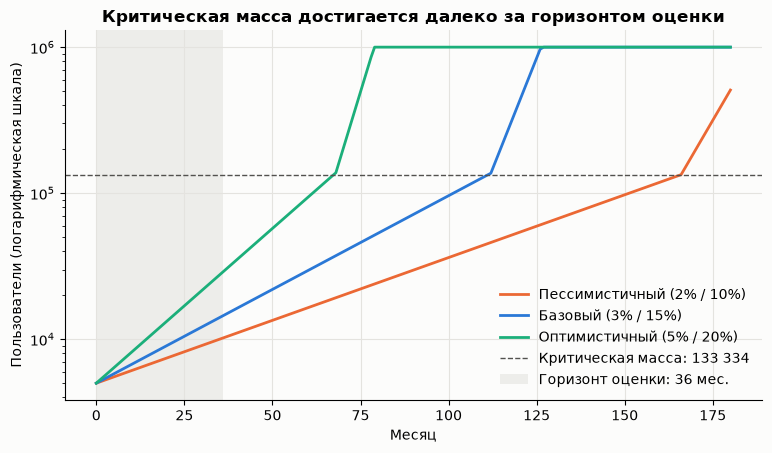

In [18]:
# График 1. Рост числа пользователей в трех сценариях и критическая масса
fig, ax = plt.subplots()
for (name, (before, after)), color in zip(GROWTH_SCENARIOS.items(), (ORANGE, BLUE, GREEN)):
    run = simulate({**BASE, "growth_before": before, "growth_after": after},
                   months=LONG_MONTHS)
    ax.plot(run.index, run["Пользователи"], color=color, linewidth=2,
            label=f"{name} ({pct(before)} / {pct(after)})")
ax.axhline(n_crit, color=GRAY, linewidth=1, linestyle="--",
           label=f"Критическая масса: {fmt(math.ceil(n_crit))}")
# Серая полоса — горизонт оценки
ax.axvspan(0, BASE["months"], color="#e4e3df", alpha=0.6, linewidth=0,
           label=f"Горизонт оценки: {BASE['months']} мес.")
ax.set_yscale("log")                        # логарифмическая шкала: рост в разы
ax.set_xlabel("Месяц")
ax.set_ylabel("Пользователи (логарифмическая шкала)")
ax.set_title("Критическая масса достигается далеко за горизонтом оценки")
ax.legend(frameon=False, loc="lower right")
fig.savefig(os.path.join(FIG_DIR, "02_growth.png"), dpi=160, bbox_inches="tight")
plt.show()

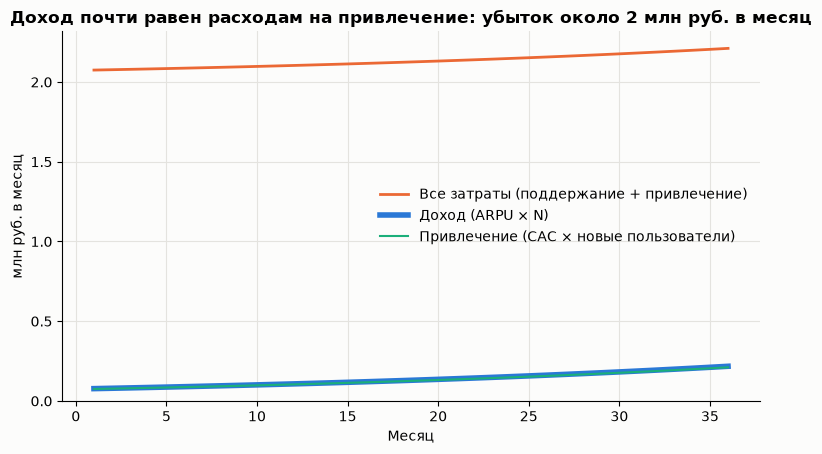

In [19]:
# График 2. Доход и затраты по месяцам в базовом варианте (без месяца 0)
flows = base_run.iloc[1:] / MLN
fig, ax = plt.subplots()
ax.plot(flows.index, flows["Поддержание"] + flows["Привлечение"], color=ORANGE,
        linewidth=2, label="Все затраты (поддержание + привлечение)")
ax.plot(flows.index, flows["Доход"], color=BLUE, linewidth=4, label="Доход (ARPU × N)")
ax.plot(flows.index, flows["Привлечение"], color=GREEN, linewidth=1.5,
        label="Привлечение (CAC × новые пользователи)")
ax.set_ylim(bottom=0)
ax.set_xlabel("Месяц")
ax.set_ylabel("млн руб. в месяц")
ax.set_title("Доход почти равен расходам на привлечение: убыток около 2 млн руб. в месяц")
ax.legend(frameon=False, loc="center right")
fig.savefig(os.path.join(FIG_DIR, "02_revenue_costs.png"), dpi=160, bbox_inches="tight")
plt.show()

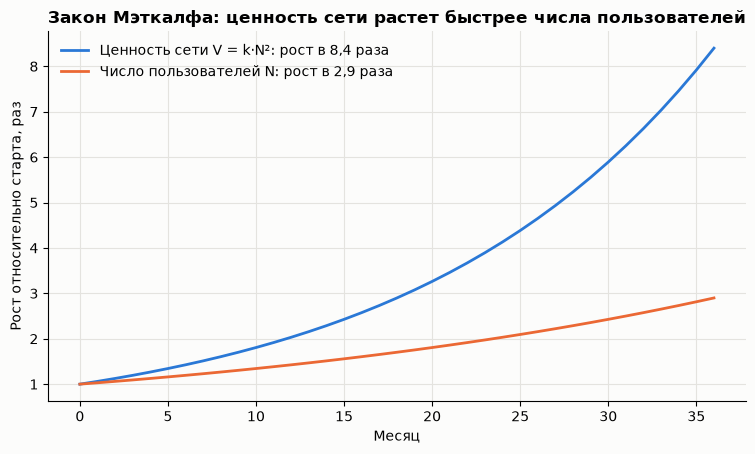

In [20]:
# График 3. Закон Мэткалфа: во сколько раз выросли пользователи и ценность сети
users_index = base_run["Пользователи"] / n_start
value_index = base_run["Ценность"] / v_start
fig, ax = plt.subplots()
ax.plot(base_run.index, value_index, color=BLUE, linewidth=2,
        label=f"Ценность сети V = k·N²: рост в {fmt(value_index.iloc[-1], 1)} раза")
ax.plot(base_run.index, users_index, color=ORANGE, linewidth=2,
        label=f"Число пользователей N: рост в {fmt(users_index.iloc[-1], 1)} раза")
ax.set_xlabel("Месяц")
ax.set_ylabel("Рост относительно старта, раз")
ax.set_title("Закон Мэткалфа: ценность сети растет быстрее числа пользователей")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "02_metcalfe.png"), dpi=160, bbox_inches="tight")
plt.show()

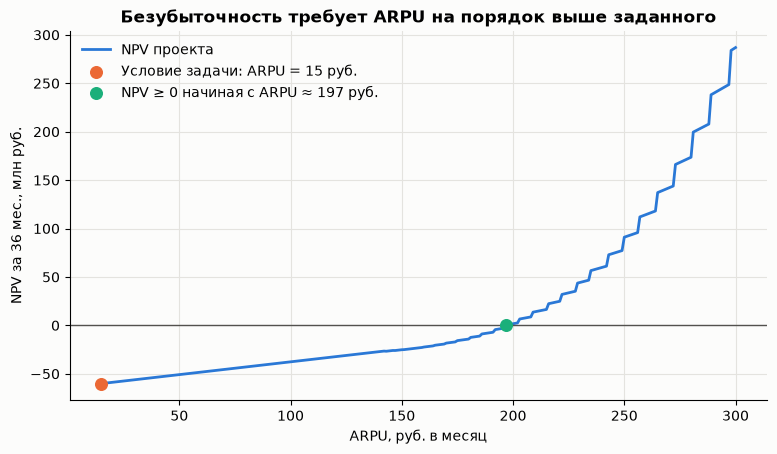

In [21]:
# График 4. NPV в зависимости от ARPU
fig, ax = plt.subplots()
ax.plot(arpu_grid, npv_curve / MLN, color=BLUE, linewidth=2, label="NPV проекта")
ax.axhline(0, color=GRAY, linewidth=1)
# Две точки: условие задачи и граница безубыточности
ax.scatter([BASE["arpu"]], [npv_base / MLN], color=ORANGE, s=70, zorder=3,
           label=f"Условие задачи: ARPU = {fmt(BASE['arpu'])} руб.")
ax.scatter([arpu_min], [npv_at_arpu(arpu_min) / MLN], color=GREEN, s=70, zorder=3,
           label=f"NPV ≥ 0 начиная с ARPU ≈ {arpu_min} руб.")
ax.set_xlabel("ARPU, руб. в месяц")
ax.set_ylabel(f"NPV за {BASE['months']} мес., млн руб.")
ax.set_title("Безубыточность требует ARPU на порядок выше заданного")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "02_npv_arpu.png"), dpi=160, bbox_inches="tight")
plt.show()

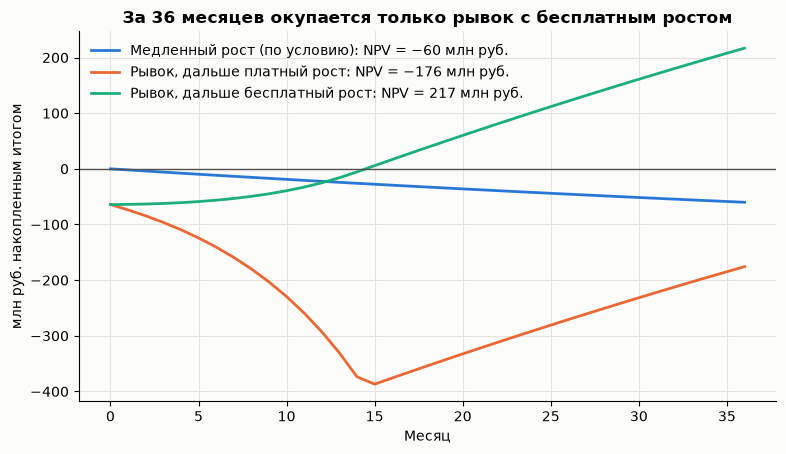

In [22]:
# График 5. Накопленный дисконтированный денежный поток по стратегиям
fig, ax = plt.subplots()
for (name, run), color in zip(strategy_runs.items(), (BLUE, ORANGE, GREEN)):
    total = run["Дисконтированная прибыль"].cumsum() / MLN
    ax.plot(run.index, total, color=color, linewidth=2,
            label=f"{name}: NPV = {fmt(total.iloc[-1])} млн руб.")
ax.axhline(0, color=GRAY, linewidth=1)
ax.set_xlabel("Месяц")
ax.set_ylabel("млн руб. накопленным итогом")
ax.set_title(f"За {BASE['months']} месяцев окупается только рывок с бесплатным ростом")
ax.legend(frameon=False, loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "02_strategies.png"), dpi=160, bbox_inches="tight")
plt.show()

In [23]:
# Сохраняем главные показатели в файл reports/02_summary.json
summary = {
    "critical_mass": n_crit,
    "critical_mass_month": t_crit,
    "critical_mass_month_exact": t_exact,
    "users_at_horizon": n_end,
    "value_start": v_start,
    "value_at_horizon": v_end,
    "revenue_total": revenue_total,
    "support_total": support_total,
    "cac_total": cac_total,
    "profit_total": profit_total,
    "npv": npv_base,
    "npv_by_growth_scenario": scenario_npv,
    "min_arpu_steady_growth": arpu_steady,
    "min_arpu": arpu_exact,
    "boost_users": extra_users,
    "boost_cost": extra_cost,
    "users_to_critical_mass": users_to_buy,
    "cac_to_critical_mass": path_cac,
    "npv_by_strategy": {name: npv(run) for name, run in strategy_runs.items()},
}
with open(os.path.join("..", "reports", "02_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Показатели сохранены в reports/02_summary.json")

Показатели сохранены в reports/02_summary.json


## 3. Анализ результатов

### 3.1. Интерпретация полученных данных

- **Критическая масса — 133 334 пользователя (13,3% населения города).** Это в 26,7 раза больше стартовой базы.
- **При росте 3% в месяц сеть дойдет до нее только на 112-м месяце** (больше 9 лет) — втрое позже конца горизонта.
  За 36 месяцев сеть вырастает до 14,5 тыс. пользователей, это 10,9% критической массы.
- **Сеть теряет около 2 млн руб. каждый месяц.** Доход с пользователя (15 руб.) целиком уходит на оплату роста
  (500 руб. × 3% = 15 руб.), и на поддержание не остается ничего. За 36 месяцев доход 4,89 млн руб., а затраты
  76,75 млн руб. (72,00 поддержание и 4,75 привлечение).
- **NPV = −60,10 млн руб.** При заданных параметрах проект убыточен.
- **Привлечение не окупается за горизонт.** CAC возвращается за 33,3 месяца, а с учетом дисконтирования пользователь
  за 36 месяцев приносит 452 руб. при цене привлечения 500 руб.
- **Закон Мэткалфа.** Пользователей стало больше в 2,9 раза, а ценность сети выросла в 8,4 раза (с 0,125 до
  1,05 млн руб.): ценность растет как квадрат числа пользователей. При критической массе она была бы 88,9 млн руб.,
  при охвате всего города — 5 млрд руб. То есть основная ценность возникает на поздних стадиях, до которых проект
  в базовом варианте не доходит. Закон Мэткалфа — оценка сверху: по более осторожному закону Одлыжко
  ($V \sim N \ln N$) ценность выросла бы только в 3,3 раза.

### 3.2. Сравнение с альтернативными вариантами

- **Темпы роста (задание 7).** NPV почти не меняется: −59,09 млн руб. в пессимистичном сценарии, −60,10 в базовом,
  −63,74 в оптимистичном. Быстрый рост внутри горизонта даже ухудшает результат: расходов на привлечение больше,
  а критическая масса все равно не достигается (в лучшем случае — на 68-м месяце).
- **Минимальный ARPU (задание 8).** Проект перестает быть убыточным при ARPU около 197 руб. в месяц — в 13 раз выше
  заданного. В этой точке NPV меняется скачком: при 196 руб. он равен −2,86 млн руб., при 197 руб. уже +0,49 млн руб.
  Причина — критическая масса $F / ARPU$ опускается до 10 164 пользователей, сеть набирает их к 24-му месяцу
  и с 25-го растет на 15%. Если темп роста не меняется, нужен ARPU 242,6 руб.
- **Ускорение на 6 месяцев (задание 9).** Нужно разово привлечь на старте 970 пользователей, это 485 тыс. руб.
  Критическая масса тогда достигается на 106-м месяце вместо 112-го. Внутри 36 месяцев эти вложения не окупаются
  (NPV снижается на 0,46 млн руб.), выигрыш появляется позже: на отрезке 15 лет NPV улучшается на 19,7 млн руб.
- **Стратегии запуска (сверх условия).** Привлечение до критической массы стоит 64,2 млн руб. при любой скорости,
  а медленный путь добавляет к этому 112 месяцев поддержания по 2 млн руб. Если купить недостающих пользователей
  сразу и дальше сеть растет бесплатно, рынок насыщается на 15-м месяце, и NPV за 36 месяцев равен +216,9 млн руб.
  Если и дальше платить по 500 руб. за пользователя, NPV за 36 месяцев равен −175,7 млн руб., а окупаемость
  наступает только на 58-м месяце. Медленный рост по условию не окупается и за 15 лет.

## 4. Выводы и рекомендации

### 4.1. Ключевые выводы

1. Критическая масса сети — **133 334 пользователя**. При заданном росте 3% она достигается на **112-м месяце**,
   далеко за горизонтом оценки.
2. NPV за 36 месяцев — **−60,10 млн руб.**; в пессимистичном и оптимистичном сценариях −59,09 и −63,74 млн руб.
3. Причина убытков — сочетание низкого ARPU, дорогого привлечения и высоких постоянных затрат: при росте 3% весь
   доход уходит на покупку пользователей.
4. Проект перестает быть убыточным при ARPU около **197 руб.** в месяц; ускорение на 6 месяцев стоит
   **485 тыс. руб.**
5. За 36 месяцев проект окупается только в одном случае: быстрый набор критической массы и бесплатный рост после нее.
   Значит, судьбу проекта решает сетевой эффект, а не объем рекламы.

### 4.2. Практические рекомендации для «ГородСоцСеть» (задание 10)

1. **Не растягивать путь до критической массы.** Каждый месяц ожидания стоит 2 млн руб. Бюджет на привлечение лучше
   потратить в начале, а не размазывать на годы.
2. **Набирать критическую массу локально.** Запускаться не на весь город сразу, а по районам, вузам, жилым комплексам:
   в небольшом сообществе сеть становится полезной быстрее и дешевле.
3. **Снижать CAC за счет самого сетевого эффекта.** Приглашения друзей, вход через существующие сервисы, партнерства
   с городскими организациями — рост должен становиться бесплатным как можно раньше.
4. **Повышать ARPU.** 15 руб. в месяц не покрывают даже стоимость роста. Подходит рекламная модель из лекции:
   бесплатно для пользователей, платят местные рекламодатели; плюс платные объявления и сервисы для организаций.
5. **Снижать постоянные затраты на старте:** чем они ниже, тем ниже критическая масса.
6. **Проверить бесплатный рост на пилоте** до крупных вложений: если после локальной критической массы сеть
   не растет сама, расширять проект нельзя.
7. **Решить проблему «курицы и яйца»:** дать пользу и без сети — городские новости, афишу, сервисы, — чтобы первым
   пользователям было зачем приходить.